# Performance as a function of the similarity to the training set

How do accuracy and uncertainty of the pose-aware and the no-pose model change when the test ligands are less similar to the training data? Scaffold split, five folds.

**Similarity.** For every activity test complex, the maximum Tanimoto similarity of its ligand (ECFP4: Morgan fingerprint, radius 2, 2048 bits) to the unique ligands of the activity training set of its fold. The test complexes are grouped into five similarity bins (< 0.5, 0.5–0.6, 0.6–0.7, 0.7–0.8, ≥ 0.8).

**Metrics per bin** (test folds pooled; activity in z-units, i.e. pIC50 standardized with the training mean and standard deviation of each fold): MAE, Pearson r, the expected calibration error (ECE; 10 equal-count bins of σ within each similarity bin, ECE = Σ_b (n_b/N) |RMSE_b − σ̄_b|) and the coverage of the 90 % interval μ ± 1.645 σ. Predicted pose classes from the pose-aware model's pose-reliability score q (good q ≥ 0.8, medium, bad q ≤ 0.2), the same classes for both models.

**Data** (`data/similarity_to_training/`): `test_complexes.csv.gz` (one row per test complex: fold, ligand, maximum similarity, measured and predicted activity, predicted variance σ² of both models, predicted q), `ligands.csv.gz` (SMILES of all activity ligands) and `training_ligands.csv.gz` (training ligands of each fold), from which the similarities can be recomputed. Figures and tables are written to `output/similarity_to_training/`.

In [1]:
from pathlib import Path
import sys

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "similarity_to_training"
OUTPUT = REPO / "analysis_publication" / "output" / "similarity_to_training"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()

BINS = [0, 0.5, 0.6, 0.7, 0.8, 1.0001]
LAB = ["< 0.5", "0.5–0.6", "0.6–0.7", "0.7–0.8", "≥ 0.8"]
GOOD_Q, BAD_Q = 0.8, 0.2
MODELS = {"pose_aware": ("Pose-aware", COLORS["pose_aware"]), "no_pose": ("No-pose", COLORS["no_pose"])}
CLASSES = {"good": ("Good", COLORS["good"]), "medium": ("Medium", "tab:orange"), "bad": ("Bad", COLORS["bad"])}

d = pd.read_csv(DATA / "test_complexes.csv.gz")
d["bin"] = pd.cut(d.max_tanimoto, BINS, right=False, labels=LAB)
d["pose_class"] = np.select([d.q_pose_aware >= GOOD_Q, d.q_pose_aware <= BAD_Q], ["good", "bad"], "medium")
for m in MODELS:
    d[f"err_{m}"] = d[f"pred_{m}"] - d.target
    d[f"sigma_{m}"] = np.sqrt(d[f"variance_{m}"])


def ece(e, s, n_bins=10):
    # expected calibration error: sum_b (n_b / N) |RMSE_b - mean sigma_b|, 10 equal-count bins of sigma
    e, s = np.asarray(e), np.asarray(s)
    b = np.clip(np.digitize(s, np.quantile(s, np.linspace(0, 1, n_bins + 1))[1:-1]), 0, n_bins - 1)
    t = pd.DataFrame({"b": b, "s": s, "e2": e ** 2}).groupby("b").agg(n=("s", "size"), s=("s", "mean"), mse=("e2", "mean"))
    return float((t.n / t.n.sum() * (np.sqrt(t.mse) - t.s).abs()).sum())


print(f"{len(d):,} test complexes; median maximum similarity {d.max_tanimoto.median():.2f}, "
      f"{(d.max_tanimoto < 0.5).mean():.0%} below 0.5")

60,064 test complexes; median maximum similarity 0.70, 8% below 0.5


### Optional: recompute the similarities

Set `RECOMPUTE = True` to recompute the maximum similarities from the SMILES with RDKit and compare them with the shipped values (a few minutes).

In [2]:
RECOMPUTE = False
if RECOMPUTE:
    from rdkit import Chem, DataStructs, RDLogger
    from rdkit.Chem import AllChem
    RDLogger.DisableLog("rdApp.*")
    lig = pd.read_csv(DATA / "ligands.csv.gz").set_index("ligand_id").smiles
    train = pd.read_csv(DATA / "training_ligands.csv.gz")
    fp = {}
    def fingerprint(i):
        if i not in fp:
            fp[i] = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(lig[i]), 2, nBits=2048)
        return fp[i]
    for k in range(5):
        train_fps = [fingerprint(i) for i in train.loc[train.fold == k, "ligand_id"]]
        test_ids = d.loc[d.fold == k, "ligand_id"].unique()
        sim = {i: max(DataStructs.BulkTanimotoSimilarity(fingerprint(i), train_fps)) for i in test_ids}
        recomputed = d.loc[d.fold == k, "ligand_id"].map(sim)
        assert np.allclose(recomputed, d.loc[d.fold == k, "max_tanimoto"], atol=1e-5), f"fold {k}: similarities differ"
        print(f"fold {k}: recomputed similarities agree")

## Accuracy and calibration per similarity bin

(a) MAE and (b) ECE of both models per similarity bin (scaffold split, test folds pooled). The number of test complexes per bin is given under the bins.

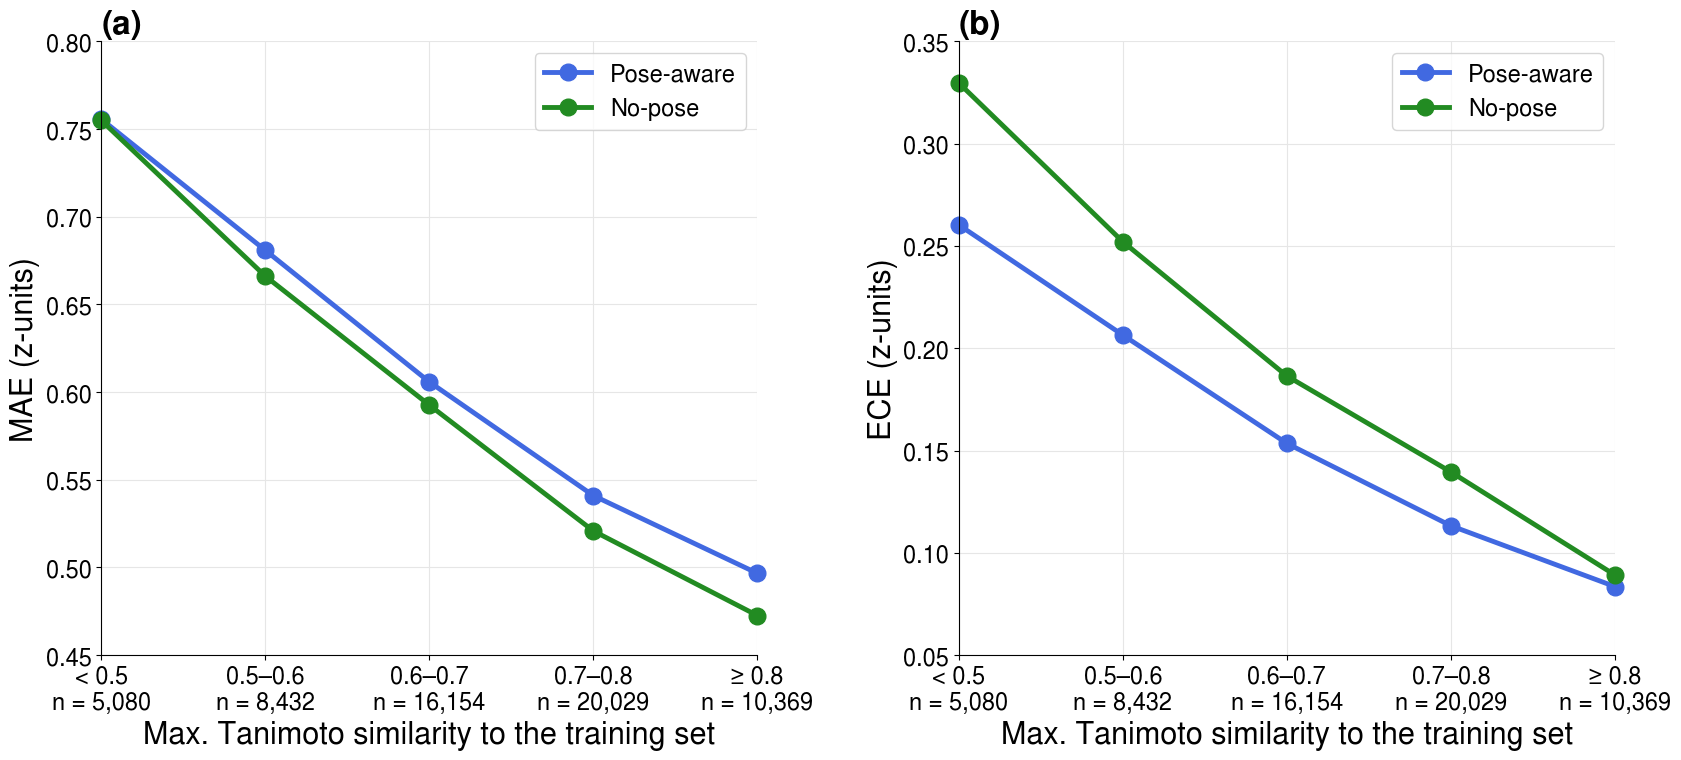

In [3]:
FS_TICK, FS_LABEL, FS_LEGEND, FS_PANEL = 17, 22, 17, 24
x = np.arange(len(LAB))
nbin = d.bin.value_counts().reindex(LAB)
ticks = [f"{b}\nn = {n:,}" for b, n in zip(LAB, nbin)]


def ylims(ax, step=0.05):
    lo, hi = ax.get_ylim()
    ax.set_ylim(np.floor(lo / step) * step, np.ceil(hi / step) * step)


fig, axes = plt.subplots(1, 2, figsize=(17, 7.8))
for ax, metric, panel in zip(axes, ["MAE", "ECE"], "ab"):
    for m, (name, color) in MODELS.items():
        y = [d.loc[d.bin == b, f"err_{m}"].abs().mean() if metric == "MAE" else ece(d.loc[d.bin == b, f"err_{m}"], d.loc[d.bin == b, f"sigma_{m}"]) for b in LAB]
        ax.plot(x, y, "o-", color=color, lw=3.5, ms=12, label=name, clip_on=False)
    ylims(ax)
    ax.set(xticks=x, xlim=(0, len(LAB) - 1))
    ax.set_ylabel(f"{metric} (z-units)", fontsize=FS_LABEL)
    ax.set_xlabel("Max. Tanimoto similarity to the training set", fontsize=FS_LABEL)
    ax.set_xticklabels(ticks)
    ax.tick_params(axis="both", labelsize=FS_TICK)
    ax.grid(True, color="0.9")
    ax.legend(loc="upper right", fontsize=FS_LEGEND)
    ax.set_title(f"({panel})", loc="left", fontweight="bold", fontsize=FS_PANEL)
fig.tight_layout(w_pad=3)
fig.savefig(OUTPUT / "similarity_to_training.png", dpi=600)
plt.show()

## Numbers per similarity bin

Folds pooled, except Δ ECE (pose-aware − no-pose, mean over the five folds) and the number of folds in which the pose-aware model has the lower ECE. Below: the correlation between the pose-aware model's predicted pose-reliability score q and the similarity, and the difference in mean σ between the two models per similarity bin, separately for the complexes predicted to have good, medium and bad poses (classes from the pose-aware q).

In [4]:
rows = []
for b in LAB:
    h = d[d.bin == b]
    dd = [ece(g.err_pose_aware, g.sigma_pose_aware) - ece(g.err_no_pose, g.sigma_no_pose) for _, g in h.groupby("fold")]
    r = {"max. similarity": b, "n": len(h)}
    for col, f in [("MAE", lambda m: h[f"err_{m}"].abs().mean()), ("Pearson r", lambda m: np.corrcoef(h[f"pred_{m}"], h.target)[0, 1]),
                   ("ECE", lambda m: ece(h[f"err_{m}"], h[f"sigma_{m}"])), ("90% coverage", lambda m: (h[f"err_{m}"].abs() <= 1.645 * h[f"sigma_{m}"]).mean())]:
        for m, (name, _) in MODELS.items():
            r[f"{col} {name}"] = f(m)
    r["Δ ECE (per fold)"] = np.mean(dd)
    r["folds pose-aware lower ECE"] = f"{sum(x < 0 for x in dd)}/{len(dd)}"
    rows.append(r)
table = pd.DataFrame(rows).set_index("max. similarity")
table.to_csv(OUTPUT / "metrics_per_similarity_bin.csv")
display(table.round(3))

offset = (d.pivot_table(index="bin", columns="pose_class", values="sigma_pose_aware", aggfunc="mean", observed=True)
          - d.pivot_table(index="bin", columns="pose_class", values="sigma_no_pose", aggfunc="mean", observed=True))[list(CLASSES)]
print(f"Spearman(q, similarity) = {stats.spearmanr(d.q_pose_aware, d.max_tanimoto).correlation:+.3f}")
display(offset.round(3).rename_axis(columns="mean σ pose-aware − no-pose, by predicted pose class"))

,n,MAE Pose-aware,MAE No-pose,Pearson r Pose-aware,Pearson r No-pose,ECE Pose-aware,ECE No-pose,90% coverage Pose-aware,90% coverage No-pose,Δ ECE (per fold),folds pose-aware lower ECE
max. similarity,,,,,,,,,,,
< 0.5,5080,0.756,0.755,0.529,0.526,0.260,0.330,0.749,0.698,-0.063,4/5
0.5–0.6,8432,0.681,0.666,0.552,0.576,0.206,0.252,0.778,0.741,-0.039,3/5
0.6–0.7,16154,0.606,0.593,0.611,0.640,0.153,0.186,0.808,0.781,-0.031,3/5
0.7–0.8,20029,0.541,0.521,0.661,0.688,0.113,0.140,0.835,0.818,-0.026,2/5
≥ 0.8,10369,0.497,0.473,0.701,0.731,0.084,0.089,0.856,0.849,-0.003,2/5


Spearman(q, similarity) = +0.011


"mean σ pose-aware − no-pose, by predicted pose class",good,medium,bad
bin,,,
< 0.5,-0.006,0.069,0.169
0.5–0.6,-0.004,0.066,0.155
0.6–0.7,-0.016,0.061,0.152
0.7–0.8,-0.015,0.051,0.140
≥ 0.8,-0.019,0.050,0.142
